# YOLOv8n Civet Detection — Training Notebook

## Step 1: Setup
Mount Google Drive, install Ultralytics, define paths and helper functions.
Run this step once per session; every later step loads its inputs from Drive.

In [1]:
# ===== Cell 1: Setup (run once per session) =====
%pip install -q ultralytics

from google.colab import drive
drive.mount('/content/drive')

import re, random, shutil
from pathlib import Path
from collections import Counter

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from ultralytics import YOLO

# ---------- Paths ----------
ROOT     = Path('/content/drive/MyDrive/civet2')
YOLO_SRC = ROOT / 'yolo'                  # Camera1..Camera4, each with images/ + labels/
MODELS   = ROOT / 'models'
RESULTS  = ROOT / 'results'
WORK     = Path('/content/yolo_data')     # local copy for fast training
RUNS     = Path('/content/yolo_runs')     # Ultralytics output (copied to Drive after training)
for d in (MODELS, RESULTS):
    d.mkdir(parents=True, exist_ok=True)

# ---------- Configuration ----------
SEED      = 42
CAM_DIRS  = ['Camera1', 'Camera2', 'Camera3', 'Camera4']
CLASSES   = ['civet']                     # single class, id 0
VAL_RATIO = 0.2                           # fraction of clips used for validation
EPOCHS    = 50
IMGSZ     = 640
IMG_EXT   = {'.jpg', '.jpeg', '.png'}
NAME_RE   = re.compile(r'(A0[1-4])_(\d{14})_t?(\d{5})')   # 't' is optional (some A04 files omit it)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# ---------- Helpers ----------
def parse_name(p):
    """A03_20260405181806_t00595.jpg -> ('A03', 'A03_20260405181806', 595) or None."""
    m = NAME_RE.search(Path(p).stem)
    if m is None:
        return None
    cam, start, t = m.groups()
    return cam, f'{cam}_{start}', int(t)

def label_path(img_path):
    """images/<name>.jpg -> labels/<name>.txt"""
    img_path = Path(img_path)
    return img_path.parent.parent / 'labels' / (img_path.stem + '.txt')

def read_boxes(img_path):
    """Return list of (cls, xc, yc, w, h); empty list if label file is missing or empty."""
    lp = label_path(img_path)
    if not lp.exists():
        return []
    boxes = []
    for line in lp.read_text().strip().splitlines():
        parts = line.split()
        if len(parts) == 5:
            boxes.append((int(parts[0]), *map(float, parts[1:])))
    return boxes

# ---------- Quick check ----------
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NOT AVAILABLE')
for cam in CAM_DIRS:
    imgs = [p for p in (YOLO_SRC / cam / 'images').glob('*') if p.suffix.lower() in IMG_EXT]
    n_lbl = sum(label_path(p).exists() for p in imgs)
    n_empty = sum(len(read_boxes(p)) == 0 for p in imgs)
    print(f'{cam}: {len(imgs):3} images | {n_lbl:3} label files | {n_empty:3} empty (no civet)')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: Tesla T4
Camera1:  75 images |  60 label files |  15 empty (no civet)
Camera2:  75 images |  60 label files |  15 empty (no civet)
Camera3:  75 images |  60 label files |  15 empty (no civet)
Camera4:  75 images |  60 label files |  15 empty (no civet)


## Step 2: Data Inventory
Scan all YOLO images and labels, check file names and label format, count images with and without the civet per camera, and show labeled samples.

Valid images: 300
Invalid file names: 0 []
Invalid label lines (class != 0 or coords outside 0-1): 0 []
Images with more than one box: 0


,images,with_civet,empty,clips
camera,,,,
A01,75,60,15,3
A02,75,60,15,2
A03,75,60,15,2
A04,75,60,15,5



Images per clip:


images  with_civet
camera clip                                  
A01    A01_20260405000000      54          45
       A01_20260405094847       6           0
       A01_20260405235925      15          15
A02    A02_20260405000000      66          60
       A02_20260405095130       9           0
A03    A03_20260405140327      41          33
       A03_20260405181806      34          27
A04    A04_20260405000000      40          35
       A04_20260405041750       1           1
       A04_20260405081938      10           0
       A04_20260405145310      23          23
       A04_20260405222742       1           1

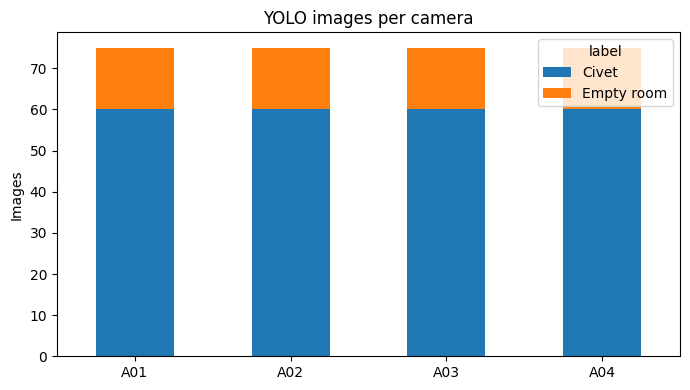

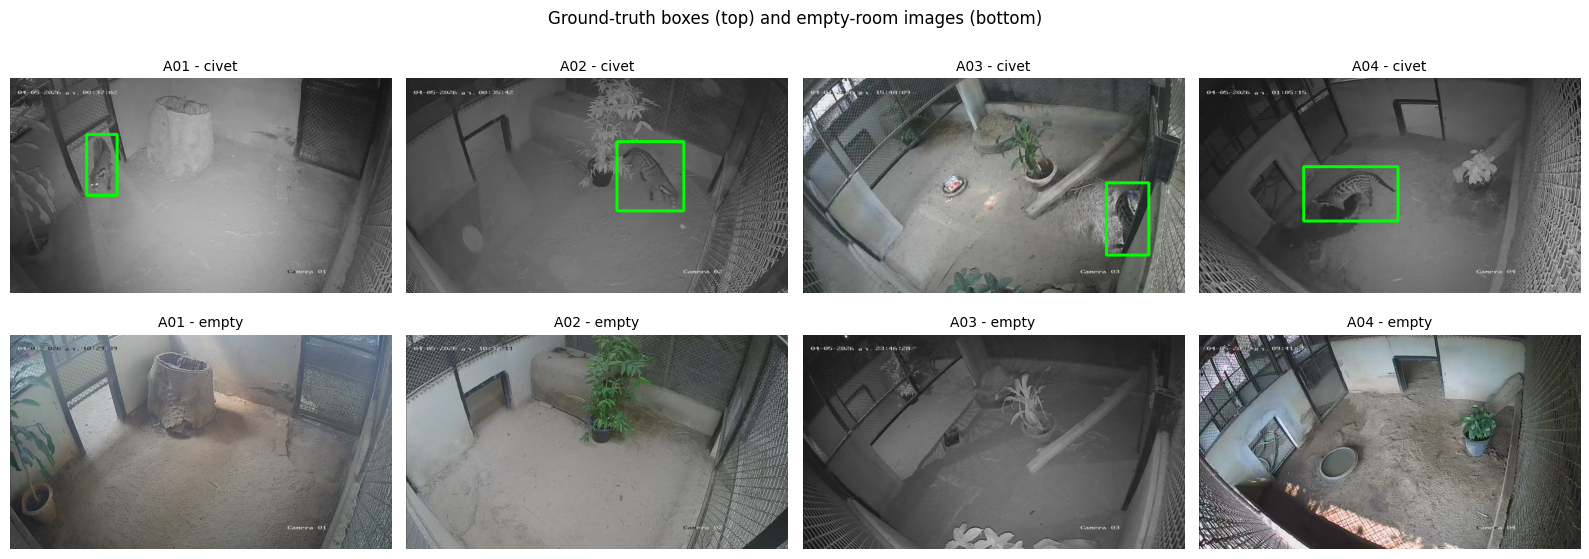


Saved: /content/drive/MyDrive/civet2/results/y2_inventory.csv


In [2]:
# ===== Cell 2: Inventory, label check and sample boxes =====
# Output: results/y2_inventory.csv (used by later cells), y2_counts.png, y2_samples.png

# ---------- Scan images and labels ----------
rows, bad_name, bad_label = [], [], []
for cam_dir in CAM_DIRS:
    for p in sorted((YOLO_SRC / cam_dir / 'images').glob('*')):
        if p.suffix.lower() not in IMG_EXT:
            continue
        info = parse_name(p)
        if info is None:
            bad_name.append(p.name); continue
        boxes = read_boxes(p)
        for b in boxes:
            if b[0] != 0 or not all(0 <= v <= 1 for v in b[1:]):
                bad_label.append((p.name, b))
        cam, clip, t = info
        rows.append({'path': str(p), 'cam_dir': cam_dir, 'camera': cam, 'clip': clip,
                     't': t, 'n_boxes': len(boxes), 'has_label_file': label_path(p).exists()})

inv = pd.DataFrame(rows)
inv['civet'] = inv['n_boxes'] > 0
print(f'Valid images: {len(inv)}')
print(f'Invalid file names: {len(bad_name)}', bad_name[:10])
print(f'Invalid label lines (class != 0 or coords outside 0-1): {len(bad_label)}', bad_label[:5])
print(f'Images with more than one box: {(inv["n_boxes"] > 1).sum()}')
assert len(inv) > 0, 'No valid images found'

# ---------- Count table per camera ----------
summary = inv.groupby('camera').agg(images=('path', 'count'),
                                    with_civet=('civet', 'sum'),
                                    empty=('civet', lambda s: (~s).sum()),
                                    clips=('clip', 'nunique'))
display(summary)
print('\nImages per clip:')
display(inv.groupby(['camera', 'clip']).agg(images=('path', 'count'),
                                            with_civet=('civet', 'sum')))

# ---------- Figure 1: images with / without civet per camera ----------
pv = (inv.assign(label=inv['civet'].map({True: 'Civet', False: 'Empty room'}))
         .pivot_table(index='camera', columns='label', values='path',
                      aggfunc='count', fill_value=0))
pv.plot(kind='bar', stacked=True, figsize=(7, 4))
plt.title('YOLO images per camera')
plt.ylabel('Images'); plt.xlabel(''); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig(RESULTS / 'y2_counts.png', dpi=120); plt.show()

# ---------- Figure 2: one labeled and one empty sample per camera ----------
def draw_boxes(img_path, color=(0, 255, 0)):
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    for _, xc, yc, bw, bh in read_boxes(img_path):
        x1, y1 = int((xc - bw / 2) * w), int((yc - bh / 2) * h)
        x2, y2 = int((xc + bw / 2) * w), int((yc + bh / 2) * h)
        cv2.rectangle(img, (x1, y1), (x2, y2), color, max(2, w // 200))
    return img

cams = sorted(inv['camera'].unique())
fig, ax = plt.subplots(2, len(cams), figsize=(4 * len(cams), 6))
ax = np.array(ax).reshape(2, -1)
for j, cam in enumerate(cams):
    for i, has in enumerate([True, False]):
        sub = inv[(inv['camera'] == cam) & (inv['civet'] == has)]
        a = ax[i, j]; a.axis('off')
        if len(sub) == 0:
            a.set_title(f'{cam}: none'); continue
        r = sub.sample(1, random_state=SEED).iloc[0]
        a.imshow(draw_boxes(r['path']))
        a.set_title(f"{cam} - {'civet' if has else 'empty'}", fontsize=10)
plt.suptitle('Ground-truth boxes (top) and empty-room images (bottom)')
plt.tight_layout(); plt.savefig(RESULTS / 'y2_samples.png', dpi=120); plt.show()

# ---------- Save inventory ----------
inv.to_csv(RESULTS / 'y2_inventory.csv', index=False)
print('\nSaved:', RESULTS / 'y2_inventory.csv')

## Step 3: Train / Validation Split
Split by time inside each clip (not random per image): for each clip and each group (civet / empty room), frames are sorted by time, the last 20% go to validation and one frame at the boundary is dropped, because neighboring frames are near-duplicates. Groups with fewer than 5 frames go to training.

split   drop       train         val      
group  civet empty civet empty civet empty
camera                                    
A01        2     2    46    10    12     3
A02        1     2    47    10    12     3
A03        2     2    46    10    12     3
A04        2     2    46    10    12     3

split
train    225
val       60
drop      15
A01: val civet=12, val empty=3
A02: val civet=12, val empty=3
A03: val civet=12, val empty=3
A04: val civet=12, val empty=3


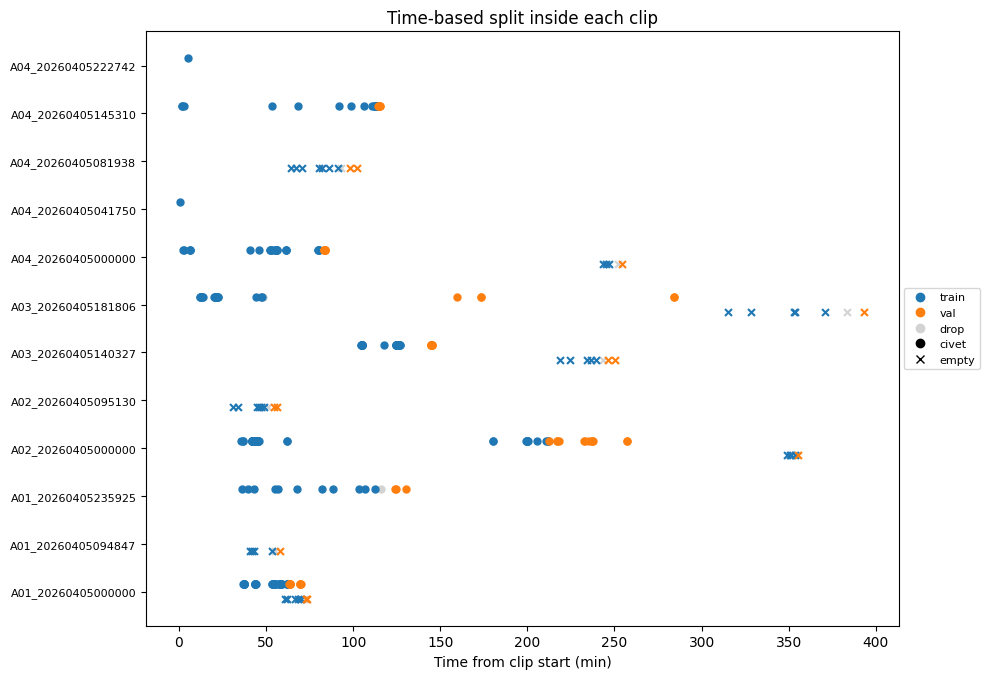

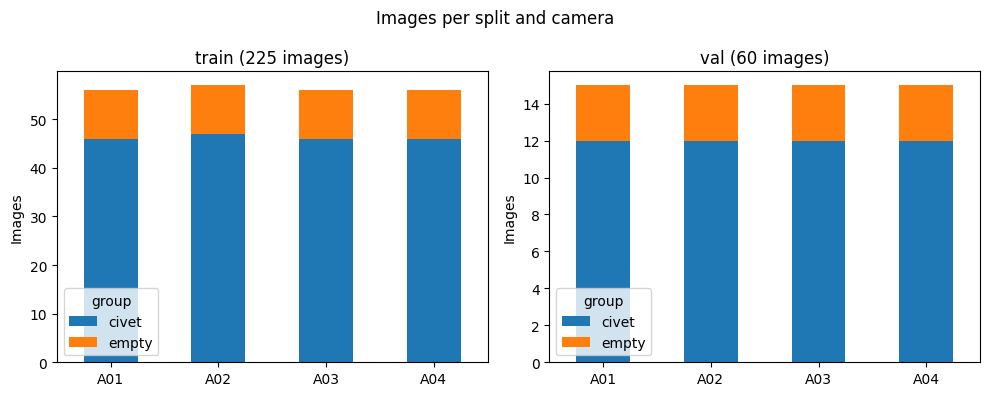


Saved: /content/drive/MyDrive/civet2/results/y3_split.csv


In [3]:
# ===== Cell 3: Time-based train / validation split =====
# Input : results/y2_inventory.csv
# Output: results/y3_split.csv (used by later cells), y3_time_split.png, y3_split_counts.png

GAP       = 1   # frames dropped between train and val in each group
MIN_GROUP = 5   # groups smaller than this go entirely to train

inv = pd.read_csv(RESULTS / 'y2_inventory.csv')
inv['civet'] = inv['civet'].astype(bool)
inv['split'] = 'train'

for (clip, civ), g in inv.groupby(['clip', 'civet']):
    if len(g) < MIN_GROUP:
        continue
    idx = g.sort_values('t').index
    n = len(idx)
    n_val = max(1, round(n * VAL_RATIO))
    inv.loc[idx[n - n_val:], 'split'] = 'val'
    inv.loc[idx[max(0, n - n_val - GAP):n - n_val], 'split'] = 'drop'

# ---------- Summary ----------
inv['group'] = inv['civet'].map({True: 'civet', False: 'empty'})
table = inv.pivot_table(index='camera', columns=['split', 'group'], values='path',
                        aggfunc='count', fill_value=0)
display(table)
print(inv['split'].value_counts().to_string())
for cam in sorted(inv['camera'].unique()):
    v = inv[(inv['camera'] == cam) & (inv['split'] == 'val')]
    print(f'{cam}: val civet={v["civet"].sum()}, val empty={(~v["civet"]).sum()}')

# ---------- Figure 1: time split per clip ----------
colors = {'train': 'tab:blue', 'val': 'tab:orange', 'drop': 'lightgray'}
clips = sorted(inv['clip'].unique())
fig, ax = plt.subplots(figsize=(10, 0.45 * len(clips) + 1.5))
for y, clip in enumerate(clips):
    g = inv[inv['clip'] == clip]
    for (sp, civ), s in g.groupby(['split', 'civet']):
        ax.scatter(s['t'] / 60, [y + (0.15 if civ else -0.15)] * len(s),
                   c=colors[sp], marker='o' if civ else 'x', s=25)
ax.set_yticks(range(len(clips))); ax.set_yticklabels(clips, fontsize=8)
ax.set_xlabel('Time from clip start (min)')
handles = [plt.Line2D([], [], color=c, marker='o', ls='', label=k) for k, c in colors.items()]
handles += [plt.Line2D([], [], color='k', marker='o', ls='', label='civet'),
            plt.Line2D([], [], color='k', marker='x', ls='', label='empty')]
ax.legend(handles=handles, fontsize=8, loc='center left', bbox_to_anchor=(1, 0.5))
plt.title('Time-based split inside each clip')
plt.tight_layout(); plt.savefig(RESULTS / 'y3_time_split.png', dpi=120); plt.show()

# ---------- Figure 2: train / val counts per camera ----------
fig, ax = plt.subplots(1, 2, figsize=(10, 4), sharey=False)
for a, sp in zip(ax, ['train', 'val']):
    (inv[inv['split'] == sp]
        .pivot_table(index='camera', columns='group', values='path', aggfunc='count', fill_value=0)
        .plot(kind='bar', stacked=True, ax=a))
    a.set_title(f'{sp} ({(inv["split"] == sp).sum()} images)')
    a.set_xlabel(''); a.set_ylabel('Images'); a.tick_params(axis='x', rotation=0)
plt.suptitle('Images per split and camera')
plt.tight_layout(); plt.savefig(RESULTS / 'y3_split_counts.png', dpi=120); plt.show()

# ---------- Save split ----------
inv.to_csv(RESULTS / 'y3_split.csv', index=False)
print('\nSaved:', RESULTS / 'y3_split.csv')

## Step 4: Build YOLO Dataset and data.yaml
Copy images and labels into the Ultralytics folder layout (`images/train`, `images/val`, `labels/train`, `labels/val`) on the local Colab disk for faster training. Empty-room images get an empty label file (background images, no civet). Then write `data.yaml` with one class: `0 = civet`.

train: 225 images | 225 label files | 185 boxes
val  : 60 images | 60 label files | 48 boxes

data.yaml:
path: /content/yolo_data
train: images/train
val: images/val
nc: 1
names: ['civet']



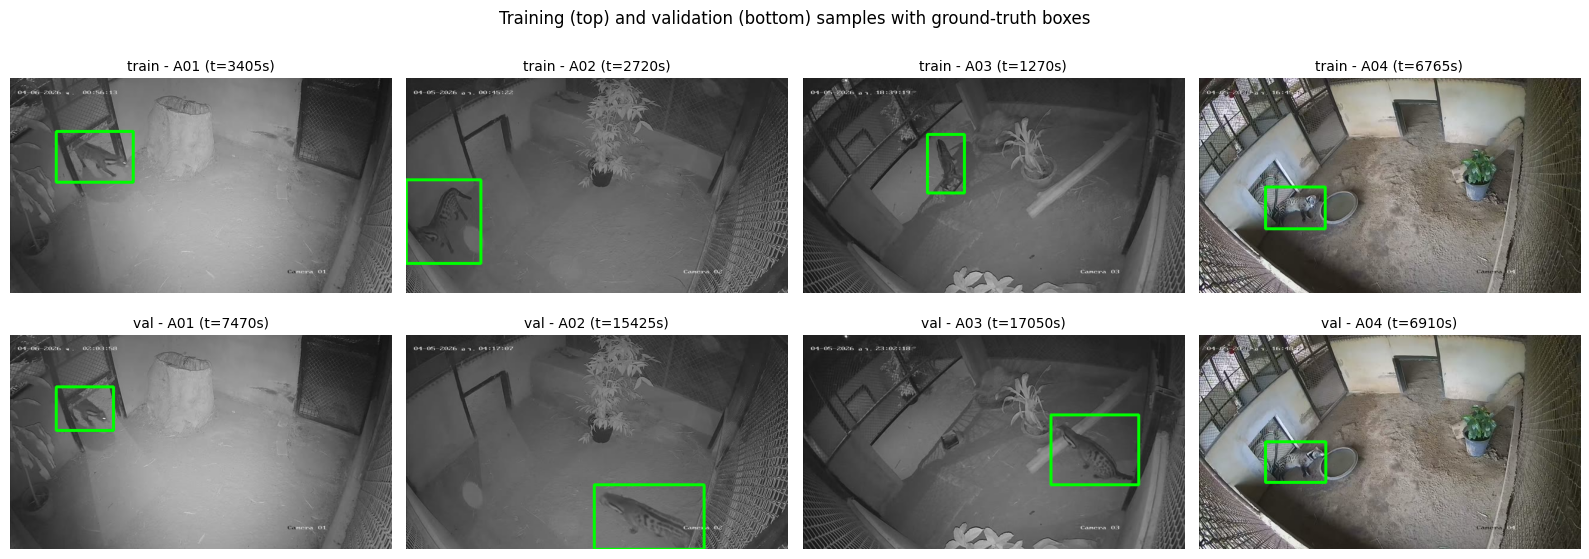

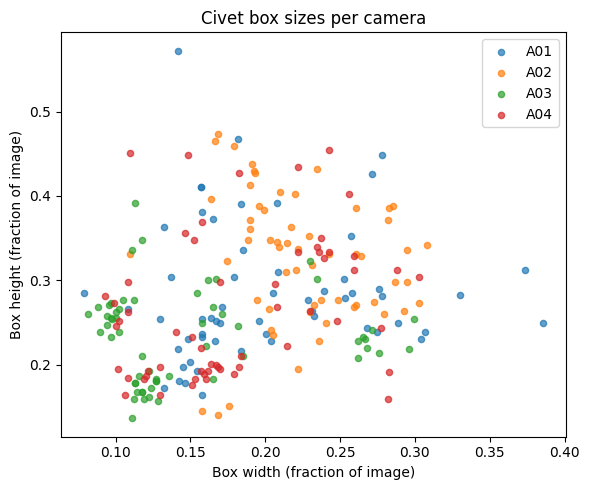

            w      h
camera              
A01     0.202  0.285
A02     0.224  0.326
A03     0.149  0.233
A04     0.180  0.266


In [4]:
# ===== Cell 4: Build local YOLO dataset and data.yaml (rerun after a disconnect) =====
# Input : results/y3_split.csv
# Output: /content/yolo_data/ (local), /content/yolo_data/data.yaml,
#         results/y4_data.yaml (copy), y4_samples.png, y4_box_sizes.png

split = pd.read_csv(RESULTS / 'y3_split.csv')
split['civet'] = split['civet'].astype(bool)
split = split[split['split'].isin(['train', 'val'])].reset_index(drop=True)

# ---------- Copy images and labels ----------
if WORK.exists():
    shutil.rmtree(WORK)                      # remove old files and label caches
for sp in ['train', 'val']:
    (WORK / 'images' / sp).mkdir(parents=True)
    (WORK / 'labels' / sp).mkdir(parents=True)

for r in split.itertuples():
    src = Path(r.path)
    shutil.copy(src, WORK / 'images' / r.split / src.name)
    dst_lbl = WORK / 'labels' / r.split / (src.stem + '.txt')
    src_lbl = label_path(src)
    if src_lbl.exists():
        shutil.copy(src_lbl, dst_lbl)
    else:
        dst_lbl.write_text('')               # background image: empty label

for sp in ['train', 'val']:
    n_img = len(list((WORK / 'images' / sp).glob('*')))
    n_lbl = len(list((WORK / 'labels' / sp).glob('*.txt')))
    n_box = sum(len(p.read_text().split()) // 5 for p in (WORK / 'labels' / sp).glob('*.txt'))
    print(f'{sp:5}: {n_img} images | {n_lbl} label files | {n_box} boxes')

# ---------- data.yaml ----------
yaml_text = (f"path: {WORK}\n"
             f"train: images/train\n"
             f"val: images/val\n"
             f"nc: {len(CLASSES)}\n"
             f"names: {CLASSES}\n")
DATA_YAML = WORK / 'data.yaml'
DATA_YAML.write_text(yaml_text)
shutil.copy(DATA_YAML, RESULTS / 'y4_data.yaml')
print('\ndata.yaml:\n' + yaml_text)

# ---------- Figure 1: training and validation samples with boxes ----------
cams = sorted(split['camera'].unique())
fig, ax = plt.subplots(2, len(cams), figsize=(4 * len(cams), 6))
for i, sp in enumerate(['train', 'val']):
    for j, cam in enumerate(cams):
        s = split[(split['split'] == sp) & (split['camera'] == cam) & split['civet']]
        r = s.sample(1, random_state=SEED).iloc[0]
        ax[i, j].imshow(draw_boxes(r['path'])); ax[i, j].axis('off')
        ax[i, j].set_title(f'{sp} - {cam} (t={r["t"]}s)', fontsize=10)
plt.suptitle('Training (top) and validation (bottom) samples with ground-truth boxes')
plt.tight_layout(); plt.savefig(RESULTS / 'y4_samples.png', dpi=120); plt.show()

# ---------- Figure 2: box size distribution ----------
box_rows = []
for r in split[split['civet']].itertuples():
    for _, xc, yc, bw, bh in read_boxes(r.path):
        box_rows.append({'camera': r.camera, 'split': r.split, 'w': bw, 'h': bh})
boxes = pd.DataFrame(box_rows)
fig, ax = plt.subplots(figsize=(6, 5))
for cam, g in boxes.groupby('camera'):
    ax.scatter(g['w'], g['h'], s=20, label=cam, alpha=0.7)
ax.set_xlabel('Box width (fraction of image)'); ax.set_ylabel('Box height (fraction of image)')
ax.set_title('Civet box sizes per camera'); ax.legend()
plt.tight_layout(); plt.savefig(RESULTS / 'y4_box_sizes.png', dpi=120); plt.show()
print(boxes.groupby('camera')[['w', 'h']].mean().round(3))

## Step 5: Model Training (YOLOv8n)
Fine-tune YOLOv8n (COCO pretrained, smallest YOLOv8 model) for one class `civet`, 50 epochs, image size 640. Ultralytics default augmentation is used (mosaic, horizontal flip, HSV color jitter, scale/translate). The best epoch is selected by validation fitness (0.1 × mAP50 + 0.9 × mAP50-95). The best model is saved to Drive as `models/yolo.pt`.

Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_data/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=civet, nbs=64, nms=None, opset=None, optimize=False, optimizer

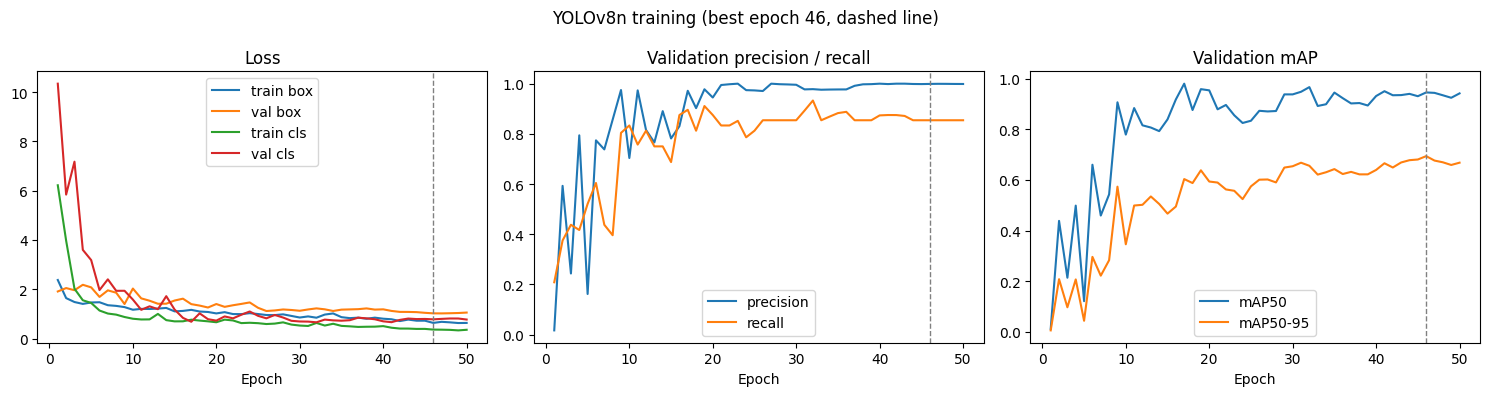

In [5]:
# ===== Cell 5: Train YOLOv8n =====
# Input : /content/yolo_data/data.yaml (Cell 4)
# Output: models/yolo.pt, models/yolo_run/ (full Ultralytics run),
#         results/y5_history.csv, y5_curves.png

DATA_YAML = WORK / 'data.yaml'
assert DATA_YAML.exists(), 'Run Cell 4 first (local dataset is missing)'

model = YOLO('yolov8n.pt')                      # COCO pretrained weights
model.train(data=str(DATA_YAML), epochs=EPOCHS, imgsz=IMGSZ, batch=16,
            seed=SEED, deterministic=True, workers=2, patience=EPOCHS,
            project=str(RUNS), name='civet', exist_ok=True, plots=True)

# ---------- Save model and run folder to Drive ----------
RUN = RUNS / 'civet'
shutil.copy(RUN / 'weights' / 'best.pt', MODELS / 'yolo.pt')
shutil.copytree(RUN, MODELS / 'yolo_run', dirs_exist_ok=True)
print('Saved:', MODELS / 'yolo.pt')

# ---------- Training history ----------
hist = pd.read_csv(RUN / 'results.csv')
hist.columns = hist.columns.str.strip()
hist['fitness'] = 0.1 * hist['metrics/mAP50(B)'] + 0.9 * hist['metrics/mAP50-95(B)']
hist.to_csv(RESULTS / 'y5_history.csv', index=False)
best = hist.loc[hist['fitness'].idxmax()]
print(f"\nBest epoch: {int(best['epoch'])}")
for k in ['metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)']:
    print(f'  {k:22} {best[k]:.3f}')

# ---------- Figure: training curves ----------
ep = hist['epoch']
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for col, lab in [('train/box_loss', 'train box'), ('val/box_loss', 'val box'),
                 ('train/cls_loss', 'train cls'), ('val/cls_loss', 'val cls')]:
    ax[0].plot(ep, hist[col], label=lab)
ax[0].set_title('Loss'); ax[0].legend()
ax[1].plot(ep, hist['metrics/precision(B)'], label='precision')
ax[1].plot(ep, hist['metrics/recall(B)'], label='recall')
ax[1].set_title('Validation precision / recall'); ax[1].legend()
ax[2].plot(ep, hist['metrics/mAP50(B)'], label='mAP50')
ax[2].plot(ep, hist['metrics/mAP50-95(B)'], label='mAP50-95')
ax[2].set_title('Validation mAP'); ax[2].legend()
for a in ax:
    a.axvline(best['epoch'], color='gray', ls='--', lw=1)
    a.set_xlabel('Epoch')
plt.suptitle(f"YOLOv8n training (best epoch {int(best['epoch'])}, dashed line)")
plt.tight_layout(); plt.savefig(RESULTS / 'y5_curves.png', dpi=120); plt.show()

## Step 6: Validation Results
Evaluate the best model on the validation set: precision, recall, mAP50, mAP50-95, PR curve and confusion matrix. Then check each validation image (IoU ≥ 0.5, confidence ≥ 0.25): results per camera, false alarms on empty-room images, and examples of missed detections and false alarms.

Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1298.2±384.1 MB/s, size: 37.8 KB)
val: Scanning /content/yolo_data/labels/val.cache... 60 images, 12 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 60/60 19.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.6it/s 1.5s
                   all         60         48      0.999      0.854      0.945      0.694
Speed: 4.4ms preprocess, 5.7ms inference, 0.0ms loss, 2.7ms postprocess per image
Results saved to /content/yolo_runs/val
YOLOv8n validation (60 images, 48 civet boxes)
Precision : 0.999
Recall    : 0.854
mAP50     : 0.945
mAP50-95  : 0.694

Saved: /content/drive/MyDrive/civet2/results/y6_pr_curve.png
Saved: /content/drive/MyDrive/civet2/results/y6_confusion.png


/tmp/ipykernel_2135/1336419475.py:73: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  cam_table = pd.concat([pi.groupby('camera').apply(cam_stats),


,images,TP,FP,FN,precision,recall,mean_IoU,empty_false_alarm,presence_acc
A01,15,12,0,0,1.0,1.0,0.881,0/3,1.0
A02,15,12,0,0,1.0,1.0,0.889,0/3,1.0
A03,15,5,0,7,1.0,0.417,0.801,0/3,0.533
A04,15,12,0,0,1.0,1.0,0.815,0/3,1.0
ALL,60,41,0,7,1.0,0.854,0.855,0/12,0.883


status
correct    53
miss        7
Saved: /content/drive/MyDrive/civet2/results/y6_report.txt


/tmp/ipykernel_2135/1336419475.py:107: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(2, len(g)), random_state=SEED)))


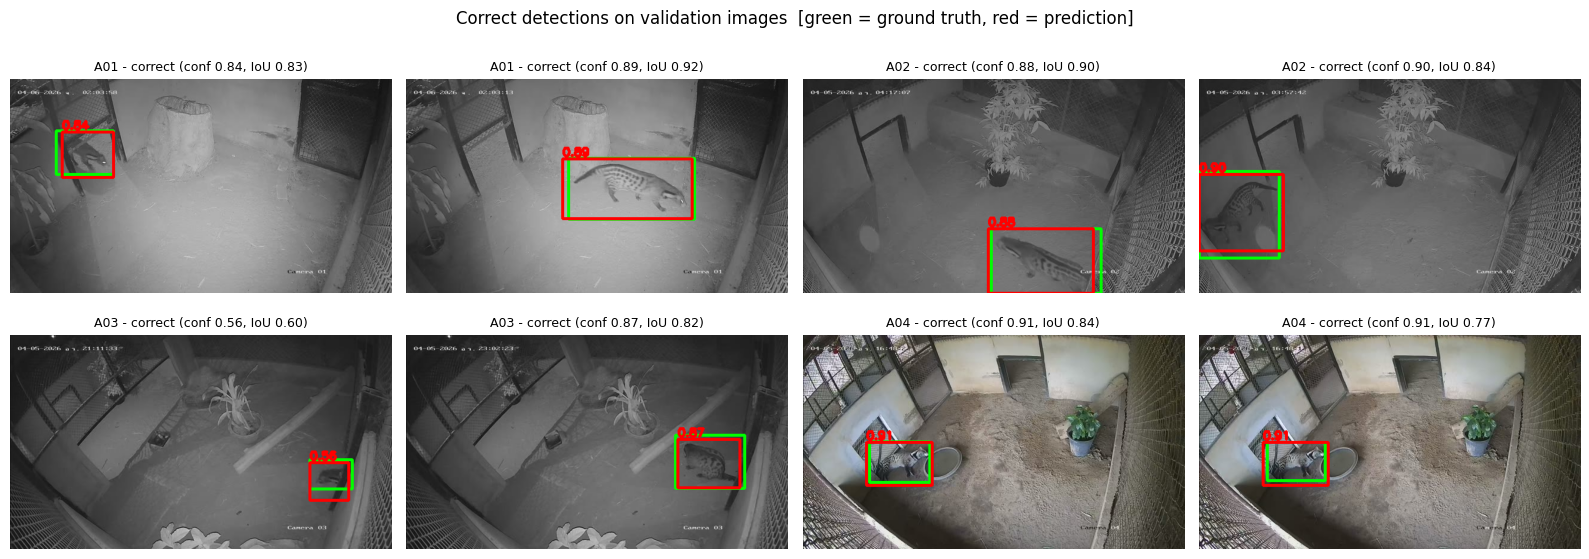

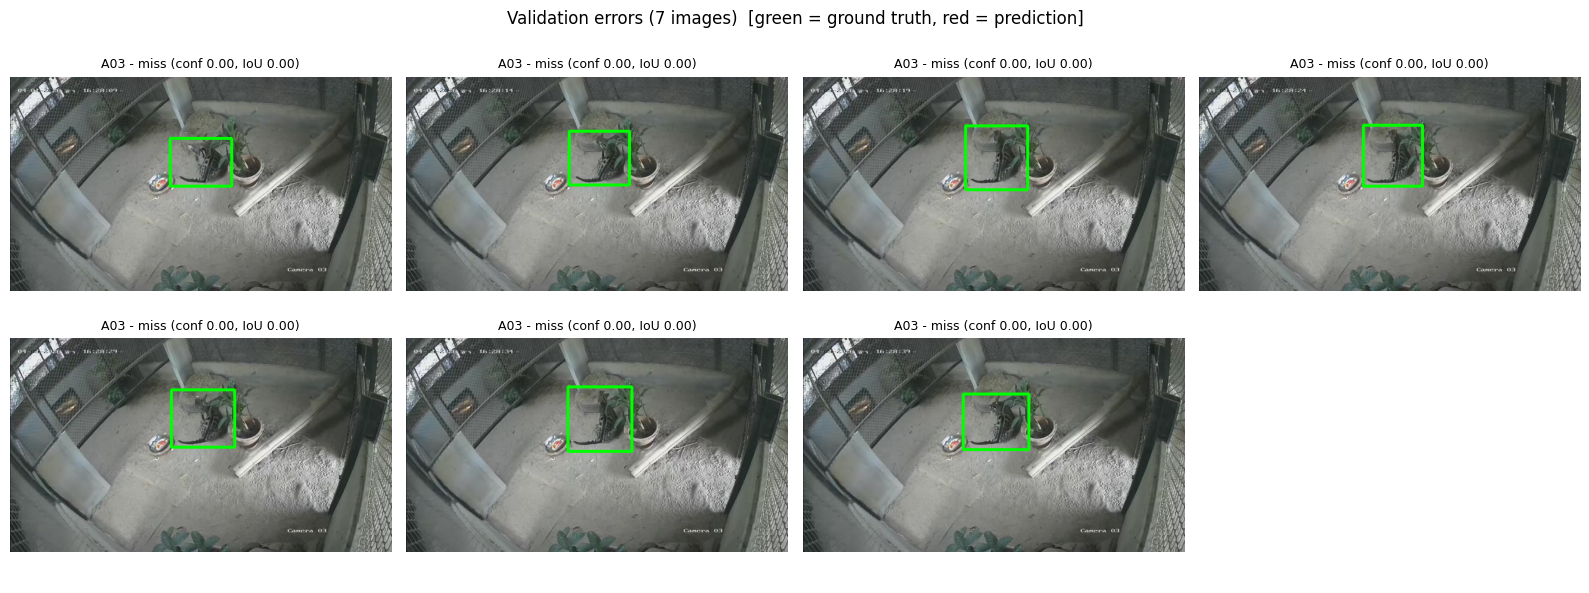

In [6]:
# ===== Cell 6: Validation results =====
# Input : models/yolo.pt, /content/yolo_data (Cell 4), results/y3_split.csv
# Output: results/y6_report.txt, y6_pr_curve.png, y6_confusion.png,
#         y6_per_image.csv, y6_predictions.png, y6_errors.png

CONF, IOU_MATCH = 0.25, 0.5
DATA_YAML = WORK / 'data.yaml'
assert DATA_YAML.exists(), 'Run Cell 4 first (local dataset is missing)'
model = YOLO(str(MODELS / 'yolo.pt'))

# ---------- Ultralytics validation metrics ----------
m = model.val(data=str(DATA_YAML), split='val', imgsz=IMGSZ, conf=0.001,
              project=str(RUNS), name='val', exist_ok=True, plots=True, verbose=False)
report = (f'YOLOv8n validation (60 images, 48 civet boxes)\n'
          f'Precision : {m.box.mp:.3f}\nRecall    : {m.box.mr:.3f}\n'
          f'mAP50     : {m.box.map50:.3f}\nmAP50-95  : {m.box.map:.3f}\n')
print(report)

VAL_DIR = RUNS / 'val'
for key, out in [('PR_curve', 'y6_pr_curve.png'), ('confusion_matrix', 'y6_confusion.png')]:
    found = sorted(VAL_DIR.glob(f'*{key}.png'))
    if found:
        shutil.copy(found[0], RESULTS / out); print('Saved:', RESULTS / out)

# ---------- Per-image check ----------
def iou(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0

def gt_xyxy(img_path, h, w):
    return [((xc - bw / 2) * w, (yc - bh / 2) * h, (xc + bw / 2) * w, (yc + bh / 2) * h)
            for _, xc, yc, bw, bh in read_boxes(img_path)]

val = pd.read_csv(RESULTS / 'y3_split.csv')
val = val[val['split'] == 'val'].reset_index(drop=True)
val['civet'] = val['civet'].astype(bool)

rows, preds = [], {}
for r, res in zip(val.itertuples(),
                  model.predict(val['path'].tolist(), conf=CONF, imgsz=IMGSZ, verbose=False, stream=True)):
    h, w = res.orig_shape
    pb = res.boxes.xyxy.cpu().numpy().tolist()
    pc = res.boxes.conf.cpu().numpy().tolist()
    preds[r.path] = (pb, pc)
    gts, used, tp, best_iou = gt_xyxy(r.path, h, w), set(), 0, 0.0
    for b in [b for _, b in sorted(zip(pc, pb), reverse=True)]:
        cand = [(iou(b, g), k) for k, g in enumerate(gts) if k not in used]
        if cand and max(cand)[0] >= IOU_MATCH:
            v, k = max(cand); used.add(k); tp += 1; best_iou = max(best_iou, v)
    rows.append({'path': r.path, 'camera': r.camera, 'civet': r.civet,
                 'n_gt': len(gts), 'n_pred': len(pb), 'tp': tp,
                 'fp': len(pb) - tp, 'fn': len(gts) - tp,
                 'max_conf': max(pc) if pc else 0.0, 'iou': round(best_iou, 3)})

pi = pd.DataFrame(rows)
pi['status'] = np.select([pi['fn'] > 0, pi['fp'] > 0], ['miss', 'false alarm'], 'correct')
pi.to_csv(RESULTS / 'y6_per_image.csv', index=False)

# ---------- Per-camera table ----------
def cam_stats(g):
    tp, fp, fn = g['tp'].sum(), g['fp'].sum(), g['fn'].sum()
    empty = g[~g['civet']]
    return pd.Series({'images': len(g), 'TP': tp, 'FP': fp, 'FN': fn,
                      'precision': round(tp / (tp + fp), 3) if tp + fp else np.nan,
                      'recall': round(tp / (tp + fn), 3) if tp + fn else np.nan,
                      'mean_IoU': round(g.loc[g['tp'] > 0, 'iou'].mean(), 3),
                      'empty_false_alarm': f"{(empty['n_pred'] > 0).sum()}/{len(empty)}",
                      'presence_acc': round(((g['n_pred'] > 0) == g['civet']).mean(), 3)})

cam_table = pd.concat([pi.groupby('camera').apply(cam_stats),
                       cam_stats(pi).to_frame('ALL').T])
display(cam_table)
print(pi['status'].value_counts().to_string())

with open(RESULTS / 'y6_report.txt', 'w') as f:
    f.write(report + f'\nPer-image check (conf >= {CONF}, IoU >= {IOU_MATCH}):\n'
            + cam_table.to_string() + '\n')
print('Saved:', RESULTS / 'y6_report.txt')

# ---------- Drawing helper: ground truth green, prediction red ----------
def draw_pred(path):
    img = draw_boxes(path, color=(0, 255, 0))
    lw = max(2, img.shape[1] // 200)
    for (x1, y1, x2, y2), c in zip(*preds[path]):
        cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)), (255, 0, 0), lw)
        cv2.putText(img, f'{c:.2f}', (int(x1), max(15, int(y1) - 5)),
                    cv2.FONT_HERSHEY_SIMPLEX, img.shape[1] / 1000, (255, 0, 0), lw)
    return img

def show_grid(df, title, fname, ncol=4):
    n = len(df); nrow = int(np.ceil(n / ncol))
    fig, ax = plt.subplots(nrow, ncol, figsize=(4 * ncol, 3 * nrow))
    ax = np.array(ax).reshape(-1)
    for a in ax: a.axis('off')
    for a, r in zip(ax, df.itertuples()):
        a.imshow(draw_pred(r.path))
        a.set_title(f'{r.camera} - {r.status} (conf {r.max_conf:.2f}, IoU {r.iou:.2f})', fontsize=9)
    plt.suptitle(title + '  [green = ground truth, red = prediction]')
    plt.tight_layout(); plt.savefig(RESULTS / fname, dpi=120); plt.show()

# ---------- Figure 1: correct predictions, 2 per camera ----------
ok = (pi[(pi['status'] == 'correct') & pi['civet']]
        .groupby('camera', group_keys=False)
        .apply(lambda g: g.sample(min(2, len(g)), random_state=SEED)))
show_grid(ok, 'Correct detections on validation images', 'y6_predictions.png')

# ---------- Figure 2: all errors (missed civet or false alarm) ----------
err = pi[pi['status'] != 'correct']
if len(err):
    show_grid(err.head(12), f'Validation errors ({len(err)} images)', 'y6_errors.png')
else:
    print('No errors on the validation set')

## Step 7: Test on the Labeled Test Hour (4 Cameras)
The detector is applied to the 4 test clips (`test/hour/`), never used in training. For each camera and each second, "civet detected" is compared with `hour_labels_by_camera.csv` (seconds without a label for that camera = civet not visible). Scoring window: 00:35:39–01:09:55; `Unclear` seconds are excluded and `In_box` counts as not visible.

### Step 7.1: Check test clips and start times

Window (whole clips): 00:00:00 - 01:13:52


,camera,start_s,fps,frames,duration_s,start,end,covers_window
0,A01,0.0,30.0,132960,4432.0,00:00:00,01:13:52,True
1,A02,0.0,30.0,108517,3617.2,00:00:00,01:00:17,False
2,A03,0.0,30.0,108270,3609.0,00:00:00,01:00:09,False
3,A04,0.0,30.0,108051,3601.7,00:00:00,01:00:01,False


Files: ['A01_20260405000000.mp4', 'A02_20260405000000-00.00.00.000-01.00.17.846.mp4', 'A03_20260405000000-00.00.00.000-01.00.09.022.mp4', 'A04_20260405000000-00.00.00.000-01.00.01.798.mp4']

hour_labels_by_camera.csv: 102 rows


,start,end,camera,behavior,note
0,00:36:58,00:37:06,A01,Locomotion,NaN
1,00:37:07,00:37:39,A01,Other,Grooming
2,00:43:36,00:44:06,A01,Locomotion,NaN
3,00:53:36,00:54:01,A01,Locomotion,NaN
4,00:54:56,00:55:13,A01,Locomotion,NaN


camera,A01,A02,A03,A04
behavior,,,,
Drinking,0,0,0,3
Feeding,0,4,5,0
Locomotion,11,17,23,14
Other,1,3,1,3
Resting,3,3,5,5
Unclear,0,0,1,0


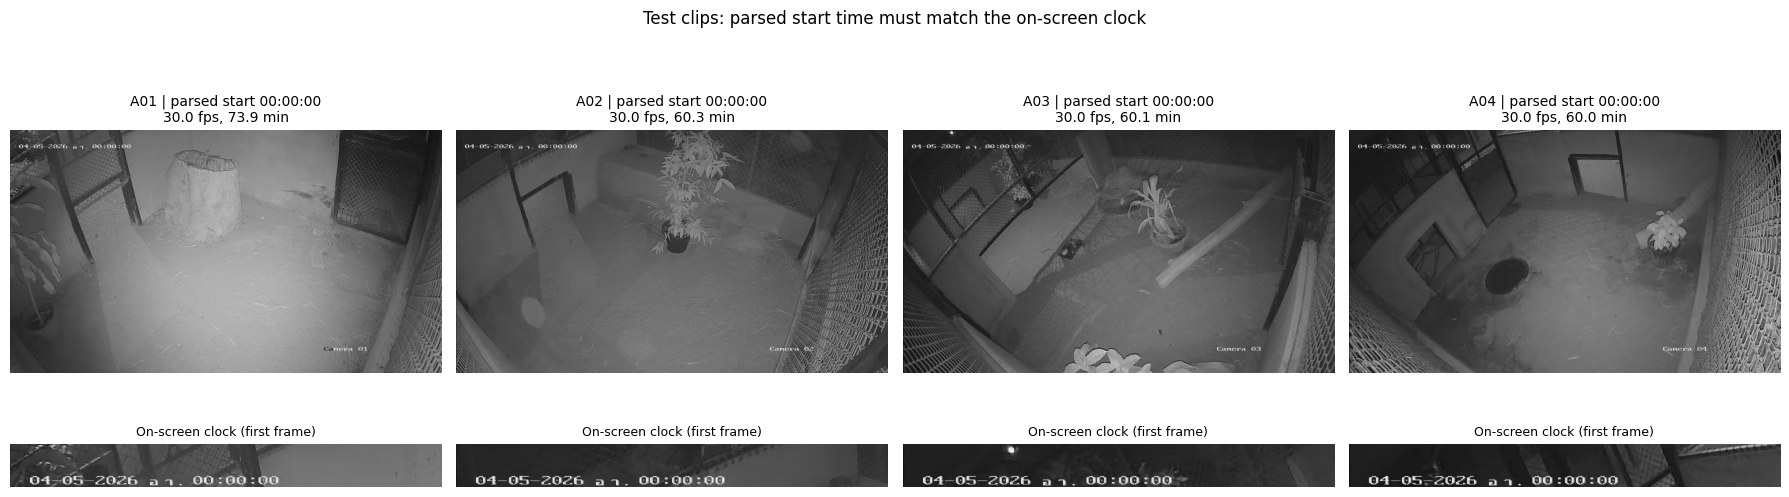

Saved: /content/drive/MyDrive/civet2/results/y7_clips.csv


In [7]:
# ===== Cell 7.1: List test clips, parse start time, check on-screen clock =====
# Output: results/y7_clips.csv (used by Cell 7.2), y7_first_frames.png

TEST     = ROOT / 'test'
HOUR_DIR = TEST / 'hour'
VID_EXT  = {'.mp4', '.avi', '.mkv', '.mov', '.dav'}

def hms_to_s(s):
    h, m, sec = map(int, s.split(':')); return h * 3600 + m * 60 + sec

def s_to_hms(s):
    s = int(s) % 86400; return f'{s // 3600:02d}:{s % 3600 // 60:02d}:{s % 60:02d}'

def parse_clip_start(name):
    """Camera and real start time (seconds after midnight) from a clip name.
    A04_20260405000000.mp4 -> 00:00:00
    A04_20260405000000-00.35.00.000-01.10.00.000.mp4 -> 00:00:00 + 00:35:00"""
    cam = re.search(r'A0[1-4]', name)
    dt = re.search(r'\d{14}', name)
    if cam is None or dt is None:
        return None, None
    hhmmss = dt.group()[-6:]
    start = int(hhmmss[:2]) * 3600 + int(hhmmss[2:4]) * 60 + int(hhmmss[4:])
    cut = re.search(r'-(\d{2})\.(\d{2})\.(\d{2})\.(\d{3})-', name)
    if cut:
        h, m, s, ms = map(int, cut.groups())
        start += h * 3600 + m * 60 + s + ms / 1000
    return cam.group(), start

# ---------- Read clip info ----------
clips = []
for p in sorted(HOUR_DIR.iterdir()):
    if p.suffix.lower() not in VID_EXT:
        continue
    cam, start = parse_clip_start(p.name)
    cap = cv2.VideoCapture(str(p))
    fps, n = cap.get(cv2.CAP_PROP_FPS), int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    ok, frame = cap.read(); cap.release()
    clips.append({'camera': cam, 'path': str(p), 'start_s': start, 'fps': round(fps, 2),
                  'frames': n, 'duration_s': round(n / fps, 1) if fps else None,
                  'first_frame': frame if ok else None})

clip_df = pd.DataFrame(clips)
clip_df['start'] = clip_df['start_s'].apply(s_to_hms)
clip_df['end'] = (clip_df['start_s'] + clip_df['duration_s']).apply(s_to_hms)
# Window = whole test clips (no fixed time)
WIN_START_S = int(clip_df['start_s'].min())
WIN_END_S = int((clip_df['start_s'] + clip_df['duration_s']).max())
WIN_START, WIN_END = s_to_hms(WIN_START_S), s_to_hms(WIN_END_S)
print('Window (whole clips):', WIN_START, '-', WIN_END)
clip_df['covers_window'] = ((clip_df['start_s'] <= hms_to_s(WIN_START)) &
                            (clip_df['start_s'] + clip_df['duration_s'] >= hms_to_s(WIN_END)))
display(clip_df.drop(columns=['first_frame', 'path']))
print('Files:', [Path(p).name for p in clip_df['path']])

# ---------- Ground-truth labels ----------
lab = pd.read_csv(TEST / 'hour_labels_by_camera.csv')
print('\nhour_labels_by_camera.csv:', len(lab), 'rows')
display(lab.head())
display(lab.pivot_table(index='behavior', columns='camera', values='start',
                        aggfunc='count', fill_value=0))

# ---------- Figure: first frame + zoomed clock of each clip ----------
fig, ax = plt.subplots(2, len(clip_df), figsize=(4.5 * len(clip_df), 5.5),
                       gridspec_kw={'height_ratios': [3, 1]})
ax = np.array(ax).reshape(2, -1)
for j, r in enumerate(clip_df.itertuples()):
    for a in ax[:, j]: a.axis('off')
    if r.first_frame is None:
        ax[0, j].set_title(f'{r.camera}: cannot read'); continue
    img = cv2.cvtColor(r.first_frame, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    ax[0, j].imshow(img)
    ax[0, j].set_title(f'{r.camera} | parsed start {r.start}\n{r.fps} fps, {r.duration_s / 60:.1f} min', fontsize=10)
    ax[1, j].imshow(img[:int(h * 0.08), :int(w * 0.45)])
    ax[1, j].set_title('On-screen clock (first frame)', fontsize=9)
plt.suptitle('Test clips: parsed start time must match the on-screen clock')
plt.tight_layout(); plt.savefig(RESULTS / 'y7_first_frames.png', dpi=120); plt.show()

clip_df.drop(columns=['first_frame']).to_csv(RESULTS / 'y7_clips.csv', index=False)
print('Saved:', RESULTS / 'y7_clips.csv')

### Step 7.2: Detect the civet every second and compare with ground truth
One frame per second is taken from each clip inside the labeled window (cut at the end of each clip). A camera "sees the civet" when YOLO returns at least one box with confidence ≥ 0.25. Ground truth: a labeled second (any behavior except `Unclear` / `In_box`) = visible; no label = not visible; `Unclear` = excluded.

Note: the test clips report 30 fps in their metadata, but only half of the frames can be decoded; the real frame rate is 15 fps, confirmed with the on-screen clock. Frame time = clip start + frame index / 15.

camera  fps  duration_s
   A01 15.0      4432.0
   A02 15.0      3617.2
   A03 15.0      3609.0
   A04 15.0      3601.7
Deleted y7_det_A01.csv
Deleted y7_det_A02.csv
Deleted y7_det_A03.csv
Deleted y7_det_A04.csv
A01: 4432/4432 seconds (00:00:00-01:13:51), failed reads: 0 -> y7_det_A01.csv
A02: 3617/3617 seconds (00:00:00-01:00:16), failed reads: 0 -> y7_det_A02.csv
A03: 3609/3609 seconds (00:00:00-01:00:08), failed reads: 0 -> y7_det_A03.csv
A04: 3601/3601 seconds (00:00:00-01:00:00), failed reads: 0 -> y7_det_A04.csv


,seconds,visible_s,TP,FP,FN,accuracy,precision,recall,F1
A01,4432.0,280.0,254.0,6.0,26.0,0.993,0.977,0.907,0.941
A02,3617.0,564.0,484.0,39.0,80.0,0.967,0.925,0.858,0.891
A03,3601.0,406.0,361.0,120.0,45.0,0.954,0.751,0.889,0.814
A04,3601.0,575.0,418.0,26.0,157.0,0.949,0.941,0.727,0.820
ALL,15251.0,1825.0,1517.0,191.0,308.0,0.967,0.888,0.831,0.859



Detection rate per ground-truth behavior (visible seconds only):


,seconds,detected_rate
gt_behavior,,
Drinking,66,0.621
Feeding,233,0.820
Locomotion,882,0.841
Other,337,0.751
Resting,307,0.945


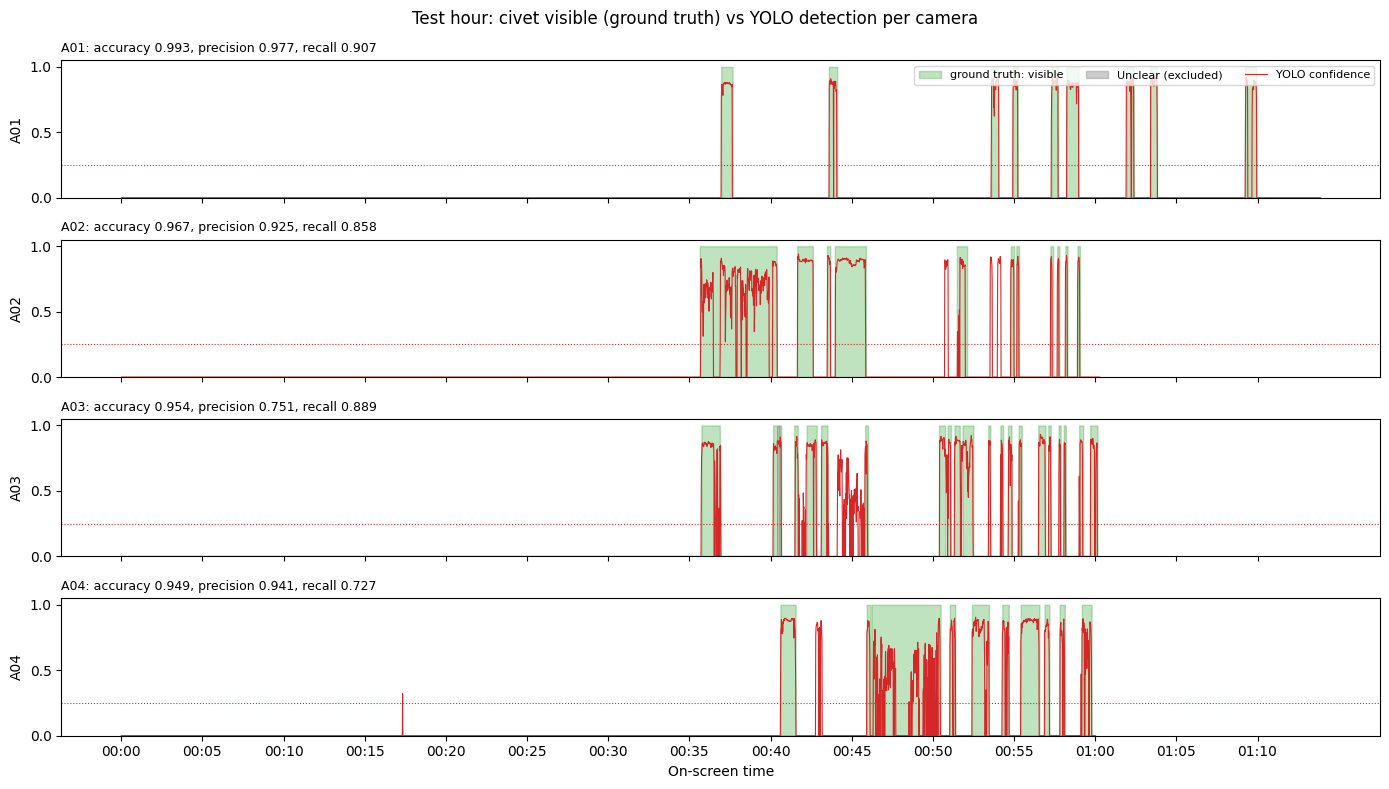

In [8]:
# ===== Cell 7.2: Per-second detection on test clips + per-camera evaluation =====
# Input : models/yolo.pt, results/y7_clips.csv, test/hour_labels_by_camera.csv
# Output: results/y7_det_<cam>.csv (one per camera, reused if present),
#         y7_detections.csv, y7_camera_eval.csv, y7_timeline.png

STEP_S, BATCH = 1, 32
CONF = 0.25               # defined in Cell 6, needed here after a restart
FORCE_RERUN = True       # Force rerun for all cameras with dynamic windows
model = YOLO(str(MODELS / 'yolo.pt'))
w0, w1 = WIN_START_S, WIN_END_S

clip_df = pd.read_csv(RESULTS / 'y7_clips.csv')
# The files report 30 fps in their metadata, but only half of the frames exist:
# the real frame rate is 15 fps (checked against the on-screen clock).
clip_df['fps'] = clip_df['fps'] / 2
print(clip_df[['camera', 'fps', 'duration_s']].to_string(index=False))

if FORCE_RERUN:
    for f in RESULTS.glob('y7_det_*.csv'):
        f.unlink(); print('Deleted', f.name)

# ---------- Detection (one CSV per camera, reused only if complete) ----------
def detect_clip(r):
    out_csv = RESULTS / f'y7_det_{r.camera}.csv'
    end_s = min(w1, int(r.start_s + r.duration_s) - 1)
    targets = list(range(w0, end_s + 1, STEP_S))
    if out_csv.exists():
        old = pd.read_csv(out_csv)
        if len(old) >= len(targets) - 5:
            print(f'{r.camera}: loaded {out_csv.name}'); return old

    rows, buf, buf_s = [], [], []
    def flush():
        for s, res in zip(buf_s, model.predict(buf, conf=CONF, imgsz=IMGSZ, verbose=False)):
            h, w = res.orig_shape
            row = {'camera': r.camera, 'sec': s, 'time': s_to_hms(s), 'n_det': len(res.boxes),
                   'conf': 0.0, 'x1': np.nan, 'y1': np.nan, 'x2': np.nan, 'y2': np.nan, 'area': 0.0}
            if len(res.boxes):
                k = int(res.boxes.conf.argmax())
                x1, y1, x2, y2 = res.boxes.xyxy[k].tolist()
                row.update(conf=float(res.boxes.conf[k]), x1=x1, y1=y1, x2=x2, y2=y2,
                           area=(x2 - x1) * (y2 - y1) / (w * h))
            rows.append(row)
        buf.clear(); buf_s.clear()

    # Sequential read from the first frame (seeking is unreliable on these clips)
    cap = cv2.VideoCapture(r.path)
    t_i, idx, fails, total_fail = 0, 0, 0, 0
    while t_i < len(targets):
        if not cap.grab():
            fails += 1; total_fail += 1
            if fails > 300:                        # end of file
                break
            continue
        fails = 0
        s = r.start_s + idx / r.fps                # on-screen time of this frame
        idx += 1
        if s >= targets[t_i]:
            ok, frame = cap.retrieve()
            if ok:
                buf.append(frame); buf_s.append(targets[t_i])
                if len(buf) == BATCH:
                    flush()
            while t_i < len(targets) and targets[t_i] <= s:
                t_i += 1
    if buf:
        flush()
    cap.release()

    det = pd.DataFrame(rows)
    det.to_csv(out_csv, index=False)
    print(f'{r.camera}: {len(det)}/{len(targets)} seconds '
          f'({s_to_hms(targets[0])}-{s_to_hms(targets[-1])}), failed reads: {total_fail} -> {out_csv.name}')
    return det

det = pd.concat([detect_clip(r) for r in clip_df.itertuples()], ignore_index=True)

# ---------- Ground truth per camera and second ----------
lab = pd.read_csv(TEST / 'hour_labels_by_camera.csv')
gt = {}
for r in lab.itertuples():
    for s in range(hms_to_s(r.start), hms_to_s(r.end) + 1):
        gt[(r.camera, s)] = r.behavior
det['gt_behavior'] = [gt.get((c, s), 'Not_visible') for c, s in zip(det['camera'], det['sec'])]
det['gt_visible'] = ~det['gt_behavior'].isin(['Not_visible', 'In_box', 'Unclear'])
det['pred_visible'] = det['n_det'] > 0
det['scored'] = det['gt_behavior'] != 'Unclear'
det.to_csv(RESULTS / 'y7_detections.csv', index=False)

# ---------- Per-camera evaluation ----------
def eval_cam(g):
    g = g[g['scored']]
    tp = (g['gt_visible'] & g['pred_visible']).sum()
    fp = (~g['gt_visible'] & g['pred_visible']).sum()
    fn = (g['gt_visible'] & ~g['pred_visible']).sum()
    p = tp / (tp + fp) if tp + fp else np.nan
    rc = tp / (tp + fn) if tp + fn else np.nan
    return pd.Series({'seconds': len(g), 'visible_s': int(g['gt_visible'].sum()),
                      'TP': tp, 'FP': fp, 'FN': fn,
                      'accuracy': round((g['gt_visible'] == g['pred_visible']).mean(), 3),
                      'precision': round(p, 3), 'recall': round(rc, 3),
                      'F1': round(2 * p * rc / (p + rc), 3) if p + rc else np.nan})

cam_eval = pd.concat([det.groupby('camera')[det.columns].apply(eval_cam),
                      eval_cam(det).to_frame('ALL').T])
display(cam_eval)
cam_eval.to_csv(RESULTS / 'y7_camera_eval.csv')

print('\nDetection rate per ground-truth behavior (visible seconds only):')
vis = det[det['scored'] & det['gt_visible']]
display(vis.groupby('gt_behavior')['pred_visible'].agg(['count', 'mean']).round(3)
           .rename(columns={'count': 'seconds', 'mean': 'detected_rate'}))

# ---------- Figure: timeline per camera ----------
cams = sorted(det['camera'].unique())
fig, ax = plt.subplots(len(cams), 1, figsize=(14, 2 * len(cams)), sharex=True)
ax = np.atleast_1d(ax)
for a, cam in zip(ax, cams):
    g = det[det['camera'] == cam]
    x = g['sec'] / 60
    a.fill_between(x, 0, g['gt_visible'].astype(float), step='mid', color='tab:green',
                   alpha=0.3, label='ground truth: visible')
    a.fill_between(x, 0, (~g['scored']).astype(float), step='mid', color='gray',
                   alpha=0.4, label='Unclear (excluded)')
    a.plot(x, g['conf'], color='tab:red', lw=0.8, label='YOLO confidence')
    a.axhline(CONF, color='tab:red', ls=':', lw=0.8)
    a.set_ylim(0, 1.05); a.set_ylabel(cam)
    r = cam_eval.loc[cam]
    a.set_title(f"{cam}: accuracy {r['accuracy']:.3f}, precision {r['precision']:.3f}, "
                f"recall {r['recall']:.3f}", fontsize=9, loc='left')
ticks = np.arange(w0 // 300 * 5, w1 / 60 + 1, 5)
ax[-1].set_xticks(ticks)
ax[-1].set_xticklabels([s_to_hms(t * 60)[:5] for t in ticks])
ax[-1].set_xlabel('On-screen time')
ax[0].legend(fontsize=8, loc='upper right', ncol=3)
plt.suptitle('Test hour: civet visible (ground truth) vs YOLO detection per camera')
plt.tight_layout(); plt.savefig(RESULTS / 'y7_timeline.png', dpi=120); plt.show()

### Step 7.3: Which room is the civet in? (combine 4 cameras)
For each second, the room is the camera whose YOLO detection has the highest confidence (alternative: the largest box). If no camera detects the civet, the civet is assumed to be inside the sleeping box (`In_box`, rule from Section 4). A 5-second majority vote smooths short switches. Compared with the merged ground truth `hour_labels.csv` in the window covered by all 4 clips; `Unclear` seconds are excluded.

Common window: 00:00:00-01:00:00 (3601 s)
Room accuracy (3554 scored seconds, 00:00:00-01:00:00):
  highest confidence                 0.900
  largest box                        0.895
  highest confidence + 5s vote       0.903
  smoothed, civet-visible seconds only 0.756

Ground-truth seconds per room: {'In_box': 2139, 'A04': 539, 'A02': 402, 'A03': 350, 'A01': 124}


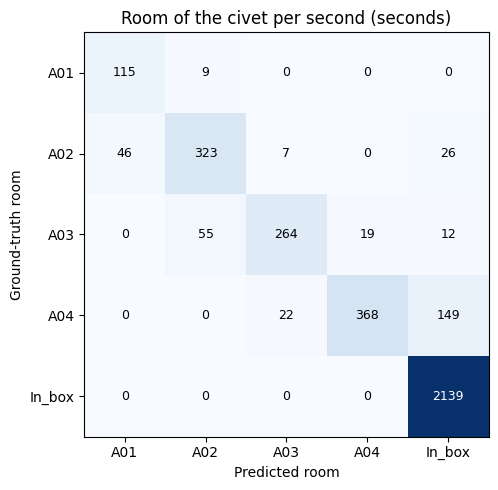

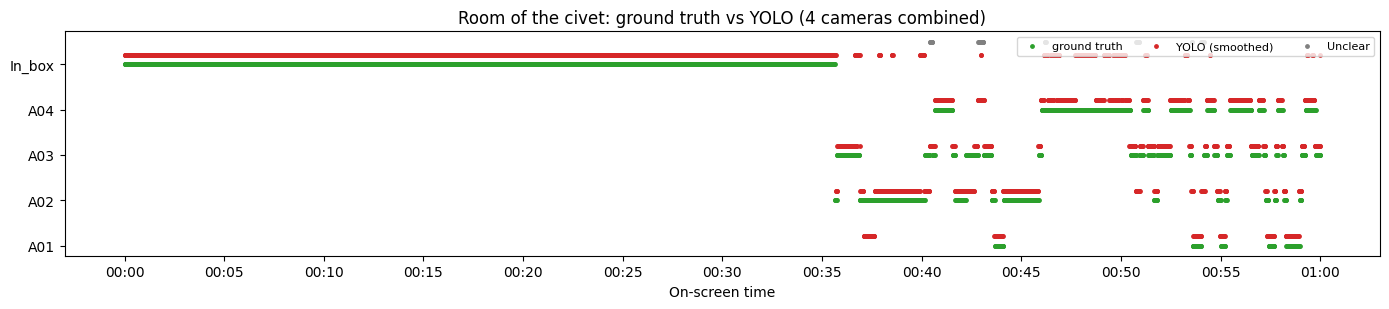

In [10]:
# ===== Cell 7.3: Room selection from 4 cameras + error examples =====
# Input : results/y7_detections.csv, y7_clips.csv, test/hour_labels.csv
# Output: results/y7_room.csv, y7_room_eval.txt, y7_room_confusion.png,
#         y7_room_timeline.png, y7_errors.png

SMOOTH_S    = 5       # majority-vote window (seconds)
SHOW_ERRORS = False   # True re-reads video for example frames (5-10 min)

det = pd.read_csv(RESULTS / 'y7_detections.csv')
clip_df = pd.read_csv(RESULTS / 'y7_clips.csv')
clip_df['fps'] = clip_df['fps'] / 2                    # real frame rate (see Cell 7.2)
cams = sorted(det['camera'].unique())
ROOMS = cams + ['In_box']
w0 = hms_to_s(WIN_START)
w_end = int(det.groupby('camera')['sec'].max().min())  # window covered by all cameras
secs = np.arange(w0, w_end + 1)
print(f'Common window: {s_to_hms(w0)}-{s_to_hms(w_end)} ({len(secs)} s)')

# ---------- Predicted room per second ----------
def pick_room(col):
    p = det.pivot_table(index='sec', columns='camera', values=col).reindex(secs).fillna(0)
    best = p.idxmax(axis=1)
    best[p.max(axis=1) <= 0] = 'In_box'                # no camera sees the civet
    return best.values

def smooth(labels, k=SMOOTH_S):
    h = k // 2
    return [Counter(labels[max(0, i - h):i + h + 1]).most_common(1)[0][0]
            for i in range(len(labels))]

room = pd.DataFrame({'sec': secs, 'time': [s_to_hms(s) for s in secs]})
room['pred_conf'] = pick_room('conf')
room['pred_area'] = pick_room('area')
room['pred_smooth'] = smooth(list(room['pred_conf']))

# ---------- Ground-truth room per second ----------
hl = pd.read_csv(TEST / 'hour_labels.csv')
gt_room = {}
for r in hl.itertuples():
    lab_room = r.behavior if r.behavior in ('Unclear', 'In_box') else r.camera
    for s in range(hms_to_s(r.start), hms_to_s(r.end) + 1):
        gt_room[s] = lab_room
room['gt'] = [gt_room.get(s, 'Unlabeled') for s in secs]
room['scored'] = ~room['gt'].isin(['Unclear', 'Unlabeled'])
room.to_csv(RESULTS / 'y7_room.csv', index=False)

sc = room[room['scored']]
vis_only = sc[sc['gt'] != 'In_box']
lines = [f'Room accuracy ({len(sc)} scored seconds, {s_to_hms(w0)}-{s_to_hms(w_end)}):']
for col, name in [('pred_conf', 'highest confidence'), ('pred_area', 'largest box'),
                  ('pred_smooth', f'highest confidence + {SMOOTH_S}s vote')]:
    lines.append(f'  {name:34} {(sc[col] == sc["gt"]).mean():.3f}')
lines.append(f'  {"smoothed, civet-visible seconds only":34} '
             f'{(vis_only["pred_smooth"] == vis_only["gt"]).mean():.3f}')
print('\n'.join(lines))
print('\nGround-truth seconds per room:', sc['gt'].value_counts().to_dict())
(RESULTS / 'y7_room_eval.txt').write_text('\n'.join(lines) + '\n')

# ---------- Figure 1: confusion matrix (smoothed) ----------
cm = pd.crosstab(sc['gt'], sc['pred_smooth']).reindex(index=ROOMS, columns=ROOMS, fill_value=0)
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm.values, cmap='Blues')
for i in range(len(ROOMS)):
    for j in range(len(ROOMS)):
        v = cm.values[i, j]
        ax.text(j, i, v, ha='center', va='center',
                color='white' if v > cm.values.max() / 2 else 'black', fontsize=9)
ax.set_xticks(range(len(ROOMS))); ax.set_xticklabels(ROOMS)
ax.set_yticks(range(len(ROOMS))); ax.set_yticklabels(ROOMS)
ax.set_xlabel('Predicted room'); ax.set_ylabel('Ground-truth room')
ax.set_title('Room of the civet per second (seconds)')
plt.tight_layout(); plt.savefig(RESULTS / 'y7_room_confusion.png', dpi=120); plt.show()

# ---------- Figure 2: room timeline ----------
ymap = {r: i for i, r in enumerate(ROOMS)}
fig, ax = plt.subplots(figsize=(14, 3.2))
ax.scatter(room['sec'] / 60, room['gt'].map(ymap), s=6, color='tab:green', label='ground truth')
ax.scatter(room['sec'] / 60, room['pred_smooth'].map(ymap) + 0.2, s=6,
           color='tab:red', label='YOLO (smoothed)')
unc = room[room['gt'] == 'Unclear']
ax.scatter(unc['sec'] / 60, [len(ROOMS) - 0.5] * len(unc), s=6, color='gray', label='Unclear')
ax.set_yticks(range(len(ROOMS))); ax.set_yticklabels(ROOMS)
ticks = np.arange(w0 // 300 * 5, w_end / 60 + 1, 5)
ax.set_xticks(ticks); ax.set_xticklabels([s_to_hms(t * 60)[:5] for t in ticks])
ax.set_xlabel('On-screen time'); ax.legend(fontsize=8, loc='upper right', ncol=3)
ax.set_title('Room of the civet: ground truth vs YOLO (4 cameras combined)')
plt.tight_layout(); plt.savefig(RESULTS / 'y7_room_timeline.png', dpi=120); plt.show()

# ---------- Figure 3: example detection errors (1 missed + 1 false alarm per camera) ----------
if SHOW_ERRORS:
    d = det[det['scored']]
    picks = []
    for cam in cams:
        g = d[d['camera'] == cam]
        for kind, mask in [('missed', g['gt_visible'] & ~g['pred_visible']),
                           ('false alarm', ~g['gt_visible'] & g['pred_visible'])]:
            if mask.any():
                picks.append((kind, g[mask].sample(1, random_state=SEED).iloc[0]))
    frames = {}
    for r in clip_df.itertuples():
        need = sorted(p['sec'] for _, p in picks if p['camera'] == r.camera)
        if not need:
            continue
        cap = cv2.VideoCapture(r.path); idx, fails, k = 0, 0, 0
        while k < len(need):
            if not cap.grab():
                fails += 1
                if fails > 300: break
                continue
            fails = 0
            s = r.start_s + idx / r.fps; idx += 1
            if s >= need[k]:
                ok, fr = cap.retrieve()
                if ok: frames[(r.camera, need[k])] = cv2.cvtColor(fr, cv2.COLOR_BGR2RGB)
                k += 1
        cap.release()
    ncol = 4; nrow = int(np.ceil(len(picks) / ncol))
    fig, ax = plt.subplots(nrow, ncol, figsize=(4 * ncol, 3 * nrow))
    ax = np.array(ax).reshape(-1)
    for a in ax: a.axis('off')
    for a, (kind, p) in zip(ax, picks):
        img = frames.get((p['camera'], p['sec']))
        if img is None: continue
        img = img.copy()
        if p['n_det'] > 0:
            cv2.rectangle(img, (int(p['x1']), int(p['y1'])), (int(p['x2']), int(p['y2'])),
                          (255, 0, 0), max(2, img.shape[1] // 200))
        a.imshow(img)
        a.set_title(f"{p['camera']} {p['time']} - {kind}\nGT: {p['gt_behavior']}, conf {p['conf']:.2f}", fontsize=9)
    plt.suptitle('Test-hour detection errors (red = YOLO box)')
    plt.tight_layout(); plt.savefig(RESULTS / 'y7_errors.png', dpi=120); plt.show()

## Step 8: Detection Rate on the ResNet Training Images
The behavior classifier will be retrained on crops from YOLO boxes, so YOLO must find the civet in almost all of its training images. YOLO is run on `sorted/` (all behavior folders + Not_visible). Missed images are listed as hard cases for extra YOLO labeling. Images from the test hour (5 Apr 00:35–01:10) are flagged and must not be used.

Images: 1700 | in test hour: 160
Copied to /content/sorted_local
  0/1700
  320/1700
  640/1700
  960/1700
  1280/1700
  1600/1700
Detection rate (visible classes should be > 0.90; Not_visible should be near 0):


camera,A01,A02,A03,A04,ALL,images
behavior,,,,,,
Drinking,NaN,NaN,NaN,1.000,1.000,24
Feeding,NaN,NaN,0.991,NaN,0.991,318
Locomotion,0.991,1.0,0.972,0.947,0.968,719
Not_visible,0.000,0.0,0.000,0.000,0.000,230
Resting,NaN,NaN,1.000,1.000,1.000,248
Sitting,1.000,1.0,0.696,0.635,0.705,88
Standing,1.000,1.0,1.000,NaN,1.000,73


Visible images detected: 0.965 (1418/1470)
Not_visible images with a detection: 0.000

Hard cases (excluding test hour): 52


camera,A01,A03,A04
case,,,
missed,1,19,32


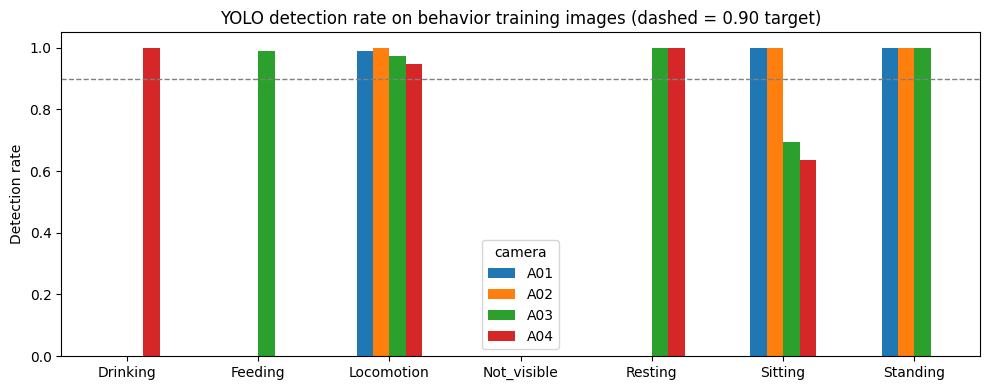

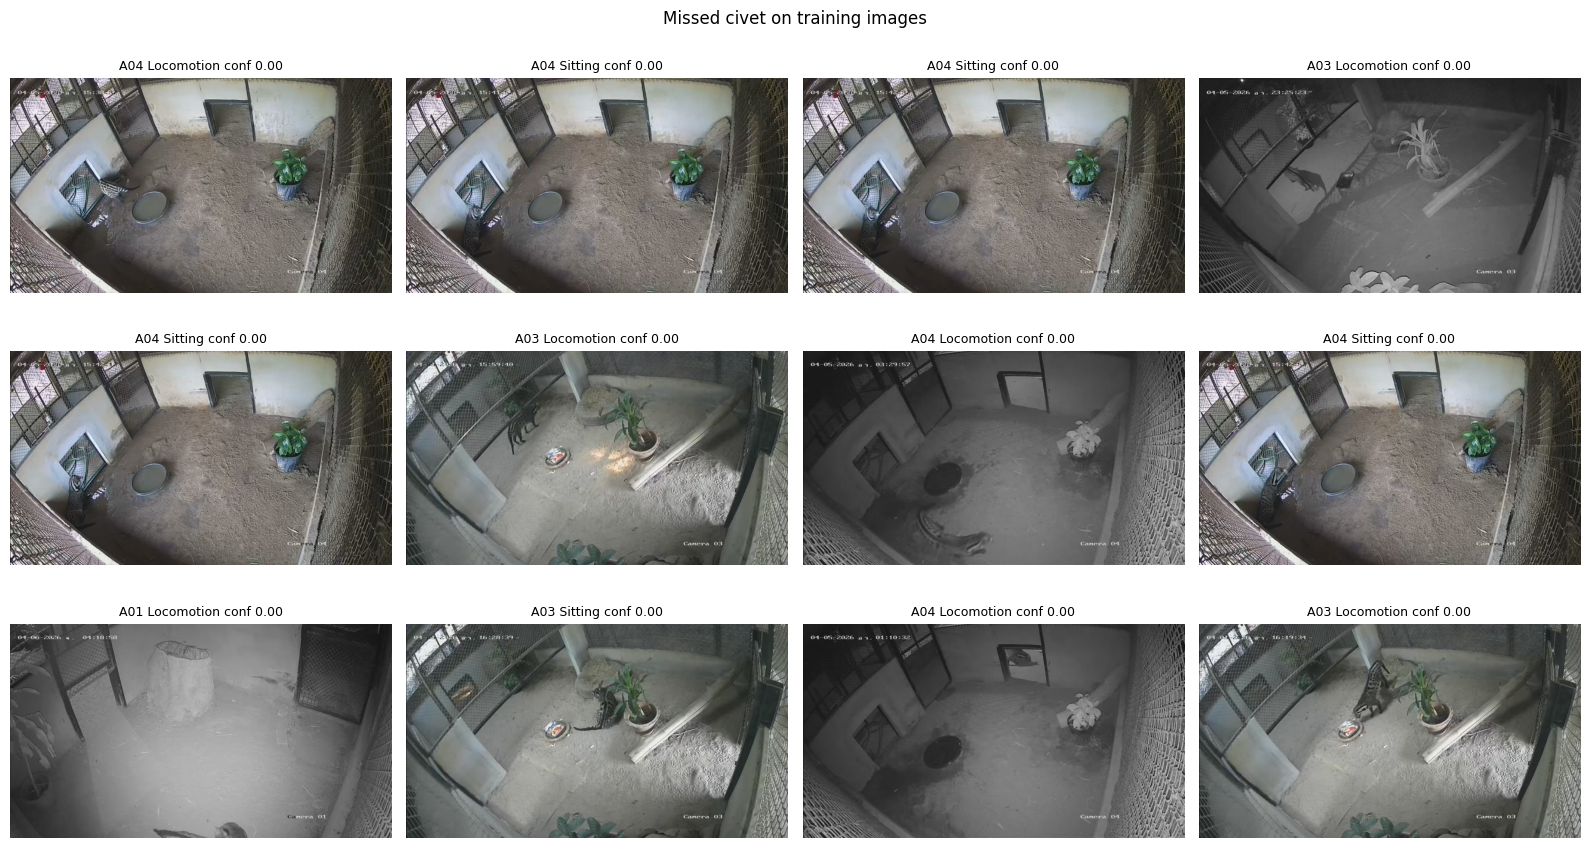

No examples for y8_notvisible_det.png


In [11]:
# ===== Cell 8: YOLO on ResNet training images (sorted/) =====
# Input : models/yolo.pt, civet2/sorted/
# Output: results/y8_sorted_det.csv, y8_hard_cases.csv, y8_rates.png,
#         y8_missed.png, y8_notvisible_det.png
from concurrent.futures import ThreadPoolExecutor

CONF = 0.25
SORTED = ROOT / 'sorted'
LOCAL = Path('/content/sorted_local')            # local copy (Drive reads are slow)
model = YOLO(str(MODELS / 'yolo.pt'))
TEST_START, TEST_END = 35 * 60, 70 * 60          # 00:35-01:10, seconds after midnight

# ---------- List images (folders starting with '_' are ignored) ----------
rows = []
for p in sorted(SORTED.rglob('*')):
    if p.suffix.lower() not in IMG_EXT or any(part.startswith('_') for part in p.relative_to(SORTED).parts):
        continue
    info = parse_name(p)
    if info is None:
        continue
    cam, clip, t = info
    start = clip.split('_')[1]                    # YYYYMMDDhhmmss
    real = (int(start[8:10]) * 3600 + int(start[10:12]) * 60 + int(start[12:14]) + t) % 86400
    rows.append({'path': str(p), 'behavior': p.parent.name, 'camera': cam,
                 'in_test_hour': start[:8] == '20260405' and TEST_START <= real <= TEST_END})
img = pd.DataFrame(rows)
img['visible'] = img['behavior'] != 'Not_visible'
print(f'Images: {len(img)} | in test hour: {img["in_test_hour"].sum()}')

# ---------- Copy images to local disk in parallel ----------
def to_local(p):
    dst = LOCAL / Path(p).relative_to(SORTED)
    if not dst.exists():
        dst.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy(p, dst)
    return str(dst)

with ThreadPoolExecutor(16) as ex:
    img['local'] = list(ex.map(to_local, img['path']))
print('Copied to', LOCAL)

# ---------- Detect (batches of 32; one big list is treated as one batch -> out of memory) ----------
res_rows, paths, B = [], img['local'].tolist(), 32
for i in range(0, len(paths), B):
    if i % 320 == 0:
        print(f'  {i}/{len(paths)}', flush=True)
    for res in model.predict(paths[i:i + B], conf=CONF, imgsz=IMGSZ, verbose=False):
        h, w = res.orig_shape
        if len(res.boxes):
            k = int(res.boxes.conf.argmax())
            x1, y1, x2, y2 = res.boxes.xyxy[k].tolist()
            res_rows.append({'n_det': len(res.boxes), 'conf': float(res.boxes.conf[k]),
                             'x1': x1, 'y1': y1, 'x2': x2, 'y2': y2,
                             'area': (x2 - x1) * (y2 - y1) / (w * h)})
        else:
            res_rows.append({'n_det': 0, 'conf': 0.0, 'x1': np.nan, 'y1': np.nan,
                             'x2': np.nan, 'y2': np.nan, 'area': 0.0})
img = pd.concat([img, pd.DataFrame(res_rows)], axis=1)
img['detected'] = img['n_det'] > 0
img.to_csv(RESULTS / 'y8_sorted_det.csv', index=False)

# ---------- Rates ----------
rate = img.pivot_table(index='behavior', columns='camera', values='detected',
                       aggfunc='mean').round(3)
rate['ALL'] = img.groupby('behavior')['detected'].mean().round(3)
rate['images'] = img.groupby('behavior').size()
print('Detection rate (visible classes should be > 0.90; Not_visible should be near 0):')
display(rate)
vis = img[img['visible']]
print(f"Visible images detected: {vis['detected'].mean():.3f} ({vis['detected'].sum()}/{len(vis)})")
print(f"Not_visible images with a detection: {img.loc[~img['visible'], 'detected'].mean():.3f}")

# ---------- Hard cases for extra labeling (test hour excluded) ----------
hard = img[(img['visible'] & ~img['detected']) | (~img['visible'] & img['detected'])].copy()
hard['case'] = np.where(hard['visible'], 'missed', 'detection on Not_visible')
hard = hard[~hard['in_test_hour']]
hard[['path', 'behavior', 'camera', 'case', 'conf']].to_csv(RESULTS / 'y8_hard_cases.csv', index=False)
print(f'\nHard cases (excluding test hour): {len(hard)}')
display(hard.groupby(['case', 'camera']).size().unstack(fill_value=0))

# ---------- Figure 1: detection rate per behavior and camera ----------
rate.drop(columns=['ALL', 'images']).plot(kind='bar', figsize=(10, 4))
plt.axhline(0.9, color='gray', ls='--', lw=1)
plt.ylabel('Detection rate'); plt.xlabel(''); plt.xticks(rotation=0); plt.ylim(0, 1.05)
plt.title('YOLO detection rate on behavior training images (dashed = 0.90 target)')
plt.tight_layout(); plt.savefig(RESULTS / 'y8_rates.png', dpi=120); plt.show()

# ---------- Figures 2-3: examples ----------
def show_examples(df, title, fname, n=12):
    if not len(df):
        print('No examples for', fname); return
    df = df.sample(min(n, len(df)), random_state=SEED)
    ncol = 4; nrow = int(np.ceil(len(df) / ncol))
    fig, ax = plt.subplots(nrow, ncol, figsize=(4 * ncol, 3 * nrow))
    ax = np.array(ax).reshape(-1)
    for a in ax: a.axis('off')
    for a, r in zip(ax, df.itertuples()):
        im = cv2.cvtColor(cv2.imread(r.local), cv2.COLOR_BGR2RGB)
        if r.n_det:
            cv2.rectangle(im, (int(r.x1), int(r.y1)), (int(r.x2), int(r.y2)),
                          (255, 0, 0), max(2, im.shape[1] // 200))
        a.imshow(im); a.set_title(f'{r.camera} {r.behavior} conf {r.conf:.2f}', fontsize=9)
    plt.suptitle(title); plt.tight_layout()
    plt.savefig(RESULTS / fname, dpi=120); plt.show()

show_examples(hard[hard['case'] == 'missed'], 'Missed civet on training images', 'y8_missed.png')
show_examples(hard[hard['case'] != 'missed'], 'Detections on Not_visible images (red = YOLO box)',
              'y8_notvisible_det.png')

  ## Step 9: Export Final Model
  The final detector is saved as `models/yolo_best.pt` for the behavior notebook.

In [12]:
   # ===== Cell 9: Export final model name for the behavior notebook =====
   shutil.copy(MODELS / 'yolo.pt', MODELS / 'yolo_best.pt')
   print('Saved:', MODELS / 'yolo_best.pt')

Saved: /content/drive/MyDrive/civet2/models/yolo_best.pt
